In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

In [2]:
DATA_DIR = Path("data/processed/12sl_median_images_final")

In [3]:
df = pd.read_csv(DATA_DIR / "training_index.csv")
metadata = pd.read_csv("ptbxl_database.csv")

In [4]:
print("Dataset shape:", df.shape)
print("Metadata shape:", metadata.shape)

Dataset shape: (20914, 158)
Metadata shape: (21799, 28)


In [5]:
df.head()

,ecg_id,image_path,label_$SABCOND,label_$SCAPTUR,label_$SFUS,label_$SIVR,label_$SRETC,label_$SWQR,label_2ST,label_AB,...,label_VESC,label_VPCX,label_VPR,label_W2T1,label_W3T1,label_W4T1,label_WPW,label_WPWA,label_WPWB,label_WQTACH
0,1,images/00001.png,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,images/00002.png,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,images/00003.png,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,images/00004.png,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,images/00005.png,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
df = df.merge(
    metadata[["ecg_id", "patient_id", "strat_fold"]],
    on="ecg_id",
    how="left",
    validate="one_to_one"
)

In [7]:
assert df["patient_id"].notna().all()
assert df["strat_fold"].notna().all()

In [8]:
print("Total ECGs:", len(df))
print("Unique patients:", df["patient_id"].nunique())
print("\nFold distribution:")
print(df["strat_fold"].value_counts().sort_index())

Total ECGs: 20914
Unique patients: 18202

Fold distribution:
strat_fold
1     2065
2     2088
3     2090
4     2100
5     2066
6     2062
7     2067
8     2070
9     2148
10    2158
Name: count, dtype: int64


In [9]:
train_df = df[df["strat_fold"].between(1, 8)].copy()
val_df = df[df["strat_fold"] == 9].copy()
test_df = df[df["strat_fold"] == 10].copy()

In [10]:
assert set(train_df.patient_id).isdisjoint(val_df.patient_id)
assert set(train_df.patient_id).isdisjoint(test_df.patient_id)
assert set(val_df.patient_id).isdisjoint(test_df.patient_id)

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nNo patient leakage detected.")

Training records: 16608
Validation records: 2148
Testing records: 2158

No patient leakage detected.


Original labels: 156
Selected labels: 10


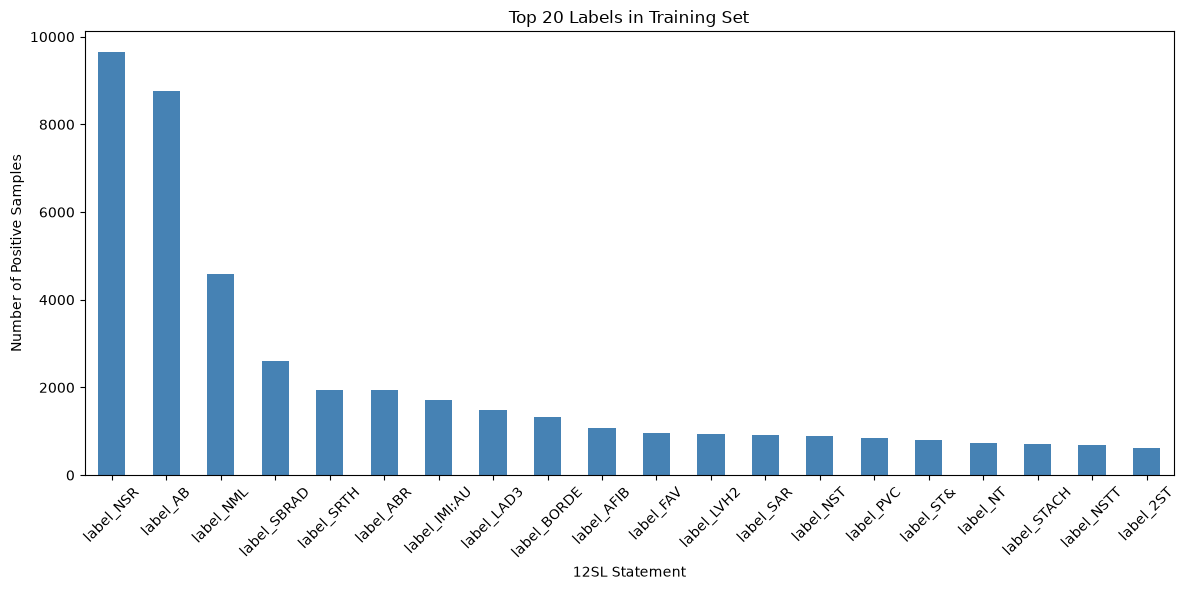

In [11]:
label_cols = [
    col for col in df.columns 
    if col.startswith("label_")
]

label_counts = train_df[label_cols].sum().sort_values(
    ascending=False
)

selected_labels = label_counts.head(10).index.tolist()

print("Original labels:", len(label_cols))
print("Selected labels:", len(selected_labels))

plt.figure(figsize=(12, 6))

label_counts.head(20).plot(kind="bar", color="steelblue")

plt.title("Top 20 Labels in Training Set")
plt.ylabel("Number of Positive Samples")
plt.xlabel("12SL Statement")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
def preprocess_ecg(image_path):

    image = Image.open(image_path).convert("RGB")
    image = np.array(image)

    panels = []

    for row in range(4):
        row_panels = []

        for col in range(3):

            x0 = 28 + 390 * col
            x1 = 391 + 390 * col

            y0 = 102 + 280 * row
            y1 = 335 + 280 * row

            panel = image[y0:y1, x0:x1]

            # Extract dark ECG trace and remove red grid
            waveform = (panel[:, :, 0] < 100).astype(
                np.uint8
            ) * 255

            row_panels.append(waveform)

        panels.append(np.concatenate(row_panels, axis=1))

    processed = np.concatenate(panels, axis=0)

    return processed

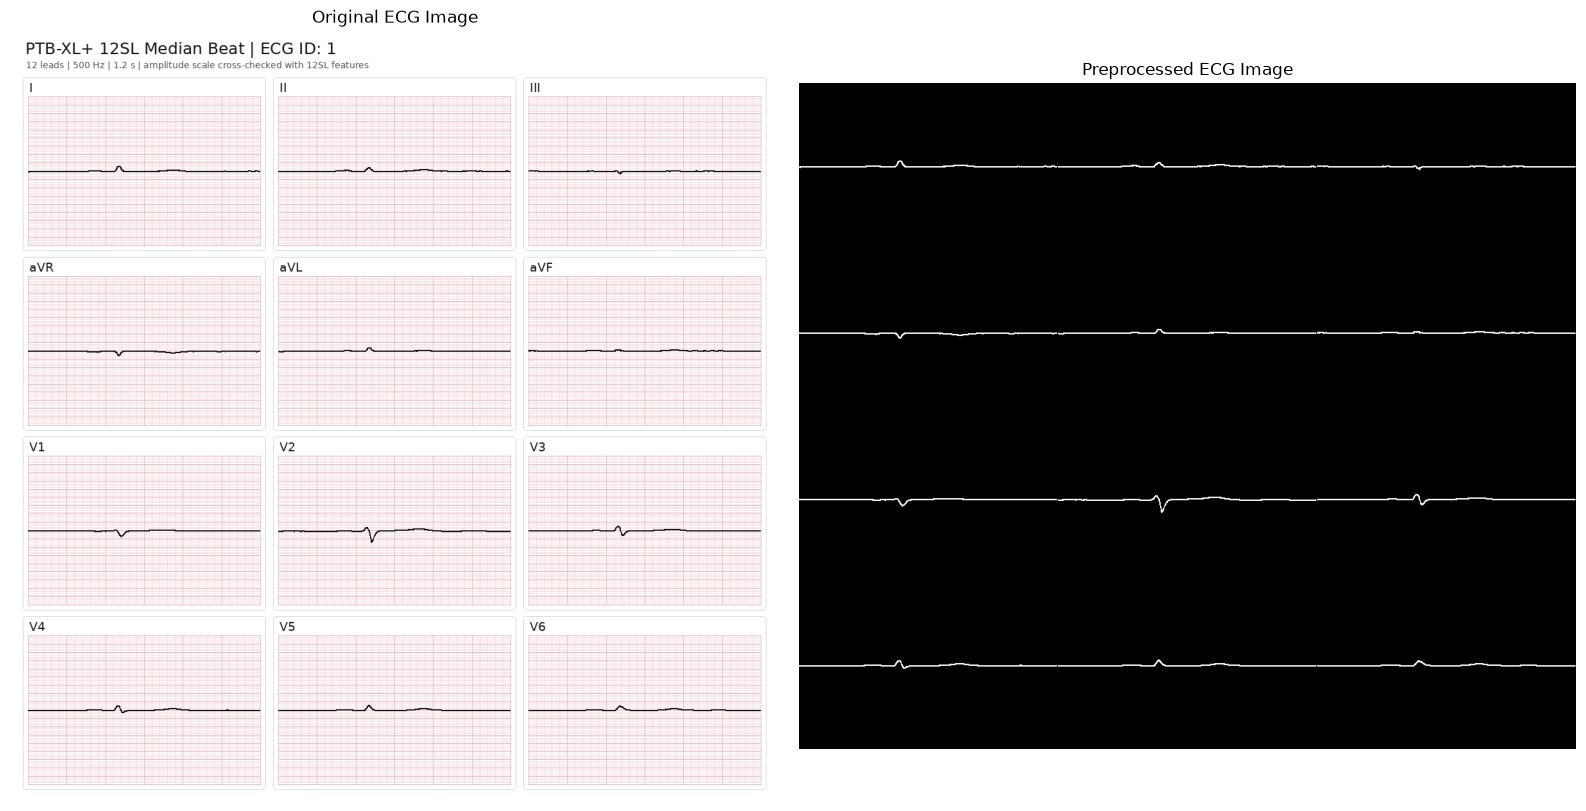

Processed image shape: (932, 1089)


In [13]:
sample = train_df.iloc[0]

image_path = DATA_DIR / sample["image_path"]

original = Image.open(image_path)
processed = preprocess_ecg(image_path)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(original)
axes[0].set_title("Original ECG Image")
axes[0].axis("off")

axes[1].imshow(processed, cmap="gray")
axes[1].set_title("Preprocessed ECG Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Processed image shape:", processed.shape)

In [14]:
distribution = pd.DataFrame({
    "Train": train_df[selected_labels].sum(),
    "Validation": val_df[selected_labels].sum(),
    "Test": test_df[selected_labels].sum()
})

print(distribution)

print("\nLabels without positive validation examples:")
print(distribution[distribution["Validation"] == 0])

print("\nLabels without positive test examples:")
print(distribution[distribution["Test"] == 0])

              Train  Validation  Test
label_NSR      9641        1253  1255
label_AB       8770        1069  1074
label_NML      4590         635   627
label_SBRAD    2594         317   342
label_SRTH     1939         255   265
label_ABR      1931         256   286
label_IMI;AU   1714         196   228
label_LAD3     1495         187   178
label_BORDE    1317         188   171
label_AFIB     1071         129   123

Labels without positive validation examples:
Empty DataFrame
Columns: [Train, Validation, Test]
Index: []

Labels without positive test examples:
Empty DataFrame
Columns: [Train, Validation, Test]
Index: []


In [15]:
import json

df.to_csv(DATA_DIR / "training_index_with_folds.csv",
          index=False)

with open(DATA_DIR / "selected_labels.json", "w") as f:
    json.dump(selected_labels, f, indent=4)

## Model Training

In [16]:
from skimage.feature import hog
from tqdm.auto import tqdm

from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score
)

import joblib

/home/ritesh_ku78/ML_P/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:
def extract_hog_features(image_path):

    image = preprocess_ecg(image_path)

    features = []

    for row in range(4):
        for col in range(3):

            lead = image[
                row * 233 : (row + 1) * 233,
                col * 363 : (col + 1) * 363
            ]

            lead_features = hog(
                lead,
                orientations=9,
                pixels_per_cell=(48, 60),
                cells_per_block=(2, 2),
                block_norm="L2-Hys",
                feature_vector=True
            )

            features.append(lead_features)

    return np.concatenate(features).astype(np.float32)

In [18]:
sample_path = DATA_DIR / train_df.iloc[0]["image_path"]

sample_features = extract_hog_features(sample_path)

print("Original preprocessed shape:",
      preprocess_ecg(sample_path).shape)

print("HOG feature shape:", sample_features.shape)
print("First 20 features:", sample_features[:20])

Original preprocessed shape: (932, 1089)
HOG feature shape: (6480,)
First 20 features: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [19]:
def prepare_features(dataframe, split_name):

    first_image = DATA_DIR / dataframe.iloc[0]["image_path"]
    n_features = len(extract_hog_features(first_image))

    X = np.empty(
        (len(dataframe), n_features),
        dtype=np.float32
    )

    for i, path in enumerate(
        tqdm(dataframe["image_path"],
             desc=f"Extracting {split_name} features")
    ):
        X[i] = extract_hog_features(DATA_DIR / path)

    y = dataframe[selected_labels].to_numpy(
        dtype=np.uint8
    )

    return X, y

In [20]:
X_train, y_train = prepare_features(train_df, "Training")
X_val, y_val = prepare_features(val_df, "Validation")
X_test, y_test = prepare_features(test_df, "Testing")

FEATURE_DIR = DATA_DIR / "hog_features"
FEATURE_DIR.mkdir(exist_ok=True)

np.save(FEATURE_DIR / "X_train.npy", X_train)
np.save(FEATURE_DIR / "X_val.npy", X_val)
np.save(FEATURE_DIR / "X_test.npy", X_test)

np.save(FEATURE_DIR / "y_train.npy", y_train)
np.save(FEATURE_DIR / "y_val.npy", y_val)
np.save(FEATURE_DIR / "y_test.npy", y_test)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Extracting Testing features: 100%|██████████| 2158/2158 [03:29<00:00, 10.29it/s]


Training: (16608, 6480) (16608, 10)
Validation: (2148, 6480) (2148, 10)
Testing: (2158, 6480) (2158, 10)


## Logistic Regression 

In [21]:
lr_model = OneVsRestClassifier(
    LogisticRegression(
        C=1.0,
        max_iter=1000,
        solver="liblinear",
        random_state=42
    ),
    n_jobs=1
)

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

joblib.dump(lr_model, DATA_DIR / "logistic_regression.pkl")

Logistic Regression training completed.


['data/processed/12sl_median_images_final/logistic_regression.pkl']

In [22]:
lr_val_probs = lr_model.predict_proba(X_val)

lr_val_preds = (lr_val_probs >= 0.5).astype(int)

print("Macro AUROC:",
      roc_auc_score(y_val, lr_val_probs, average="macro"))

print("Macro AUPRC:",
      average_precision_score(y_val, lr_val_probs,
                              average="macro"))

print("Macro F1:",
      f1_score(y_val, lr_val_preds,
               average="macro", zero_division=0))

print("Micro F1:",
      f1_score(y_val, lr_val_preds,
               average="micro", zero_division=0))

Macro AUROC: 0.8717927954380537
Macro AUPRC: 0.6134803267776768
Macro F1: 0.5167283126569526
Micro F1: 0.6929889298892989


## Random Forest

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier

In [24]:
rf_model = OneVsRestClassifier(
    RandomForestClassifier(
        n_estimators=100,
        max_depth=18,
        min_samples_leaf=3,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),
    n_jobs=1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

joblib.dump(
    rf_model,
    DATA_DIR / "random_forest.pkl"
)

Random Forest training completed.


['data/processed/12sl_median_images_final/random_forest.pkl']

In [25]:
rf_val_probs = rf_model.predict_proba(X_val)

rf_val_preds = (rf_val_probs >= 0.5).astype(int)

print("Macro AUROC:",
      roc_auc_score(y_val, rf_val_probs, average="macro"))

print("Macro AUPRC:",
      average_precision_score(y_val, rf_val_probs,
                              average="macro"))

print("Macro F1:",
      f1_score(y_val, rf_val_preds,
               average="macro", zero_division=0))

print("Micro F1:",
      f1_score(y_val, rf_val_preds,
               average="micro", zero_division=0))

Macro AUROC: 0.8720417146566746
Macro AUPRC: 0.6204928723738139
Macro F1: 0.4467055278594362
Micro F1: 0.6856195818459969


In [26]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],

    "Macro AUROC": [
        roc_auc_score(y_val, lr_val_probs, average="macro"),
        roc_auc_score(y_val, rf_val_probs, average="macro")
    ],

    "Macro AUPRC": [
        average_precision_score(y_val, lr_val_probs,
                                average="macro"),
        average_precision_score(y_val, rf_val_probs,
                                average="macro")
    ],

    "Macro F1": [
        f1_score(y_val, lr_val_preds,
                 average="macro", zero_division=0),
        f1_score(y_val, rf_val_preds,
                 average="macro", zero_division=0)
    ],

    "Micro F1": [
        f1_score(y_val, lr_val_preds, average="micro"),
        f1_score(y_val, rf_val_preds, average="micro")
    ]
})

display(results.round(4))

,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1
0,Logistic Regression,0.8718,0.6135,0.5167,0.6930
1,Random Forest,0.8720,0.6205,0.4467,0.6856


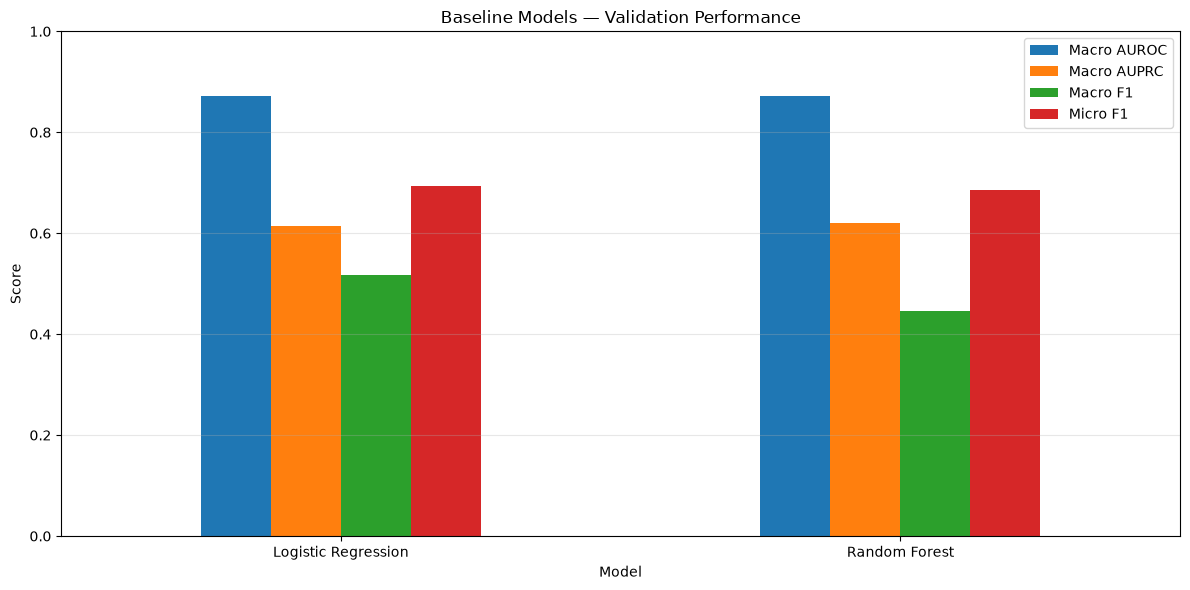

In [27]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Baseline Models — Validation Performance")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 2D CNN

In [28]:
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

In [29]:
torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 2050


In [30]:
class ECGDataset(Dataset):

    def __init__(self, dataframe, data_dir, labels):

        self.paths = dataframe["image_path"].tolist()
        self.targets = dataframe[labels].to_numpy(
            dtype=np.float32
        )
        self.data_dir = data_dir

    def __len__(self):

        return len(self.paths)

    def __getitem__(self, idx):

        image_path = self.data_dir / self.paths[idx]

        image = preprocess_ecg(image_path)

        leads = []

        for row in range(4):
            for col in range(3):

                panel = image[
                    row * 233 : (row + 1) * 233,
                    col * 363 : (col + 1) * 363
                ]

                leads.append(panel)

        image = np.stack(leads, axis=0)

        image = torch.from_numpy(image).float() / 255.0

        target = torch.from_numpy(self.targets[idx])

        return image, target

In [31]:
train_dataset = ECGDataset(
    train_df, DATA_DIR, selected_labels
)

val_dataset = ECGDataset(
    val_df, DATA_DIR, selected_labels
)

test_dataset = ECGDataset(
    test_df, DATA_DIR, selected_labels
)

In [32]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [33]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

/tmp/ipykernel_5563/3251681603.py:37: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:208.)
  target = torch.from_numpy(self.targets[idx])


Image batch shape: torch.Size([16, 12, 233, 363])
Label batch shape: torch.Size([16, 10])


In [34]:
class ECGCNN(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        def conv_block(in_channels, out_channels):

            return nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=3,
                    padding=1,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2)
            )

        self.features = nn.Sequential(
            conv_block(12, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256)
        )

        self.pool = nn.AdaptiveAvgPool2d((4, 8))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)

        return x

In [35]:
model = ECGCNN(
    num_classes=len(selected_labels)
).to(device)

print(model)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))

ECGCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(12, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=

In [36]:
EPOCHS = 30
LEARNING_RATE = 0.0003
PATIENCE = 5

In [37]:
criterion = nn.BCEWithLogitsLoss()

In [38]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

In [39]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

In [40]:
BEST_MODEL_PATH = DATA_DIR / "cnn_best.pt"

In [41]:
print("Training device:", device)
print("Number of classes:", len(selected_labels))

Training device: cuda
Number of classes: 10


In [42]:
def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    running_loss = 0.0

    for images, targets in tqdm(loader, desc="Training", leave=False):

        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad(set_to_none=True)

        # Forward propagation
        logits = model(images)

        # Calculate loss
        loss = criterion(logits, targets)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    return running_loss / len(loader.dataset)

In [43]:
def evaluate_model(model, loader, criterion):

    model.eval()

    running_loss = 0.0

    all_targets = []
    all_probs = []

    with torch.no_grad():

        for images, targets in tqdm(
            loader, desc="Evaluating", leave=False
        ):

            images = images.to(device)
            targets = targets.to(device)

            logits = model(images)

            loss = criterion(logits, targets)

            probs = torch.sigmoid(logits)

            running_loss += loss.item() * images.size(0)

            all_targets.append(targets.cpu().numpy())
            all_probs.append(probs.cpu().numpy())

    y_true = np.concatenate(all_targets, axis=0)
    y_probs = np.concatenate(all_probs, axis=0)

    y_preds = (y_probs >= 0.5).astype(int)

    metrics = {
        "loss": running_loss / len(loader.dataset),

        "macro_auroc": roc_auc_score(
            y_true, y_probs, average="macro"
        ),

        "macro_auprc": average_precision_score(
            y_true, y_probs, average="macro"
        ),

        "macro_f1": f1_score(
            y_true, y_preds,
            average="macro", zero_division=0
        ),

        "micro_f1": f1_score(
            y_true, y_preds,
            average="micro", zero_division=0
        )
    }

    return metrics, y_true, y_probs

In [44]:
history = {
    "train_loss": [],
    "val_loss": [],
    "macro_auroc": [],
    "macro_auprc": [],
    "macro_f1": [],
    "micro_f1": []
}

best_auprc = -np.inf
best_epoch = 0
epochs_without_improvement = 0

In [45]:
for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_metrics, _, _ = evaluate_model(
        model,
        val_loader,
        criterion
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_metrics["loss"])
    history["macro_auroc"].append(val_metrics["macro_auroc"])
    history["macro_auprc"].append(val_metrics["macro_auprc"])
    history["macro_f1"].append(val_metrics["macro_f1"])
    history["micro_f1"].append(val_metrics["micro_f1"])

    scheduler.step(val_metrics["macro_auprc"])

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"AUROC: {val_metrics['macro_auroc']:.4f} | "
        f"AUPRC: {val_metrics['macro_auprc']:.4f} | "
        f"Macro F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_auprc"] > best_auprc:

        best_auprc = val_metrics["macro_auprc"]
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        epochs_without_improvement = 0

        print("Best model saved.")

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print("Early stopping triggered.")
        break

Epoch [01/30] | Train Loss: 0.3163 | Val Loss: 0.2700 | AUROC: 0.8900 | AUPRC: 0.6408 | Macro F1: 0.4741
Best model saved.


Epoch [02/30] | Train Loss: 0.2532 | Val Loss: 0.2311 | AUROC: 0.9117 | AUPRC: 0.6873 | Macro F1: 0.5700
Best model saved.


Epoch [03/30] | Train Loss: 0.2353 | Val Loss: 0.2228 | AUROC: 0.9196 | AUPRC: 0.7164 | Macro F1: 0.5684
Best model saved.


Epoch [04/30] | Train Loss: 0.2229 | Val Loss: 0.2231 | AUROC: 0.9228 | AUPRC: 0.7190 | Macro F1: 0.5938
Best model saved.


Epoch [05/30] | Train Loss: 0.2150 | Val Loss: 0.2098 | AUROC: 0.9284 | AUPRC: 0.7359 | Macro F1: 0.6311
Best model saved.


Epoch [06/30] | Train Loss: 0.2084 | Val Loss: 0.2136 | AUROC: 0.9261 | AUPRC: 0.7382 | Macro F1: 0.6155
Best model saved.


... (10 outputs left out)

Epoch [17/30] | Train Loss: 0.1324 | Val Loss: 0.2548 | AUROC: 0.9280 | AUPRC: 0.7562 | Macro F1: 0.6850


Epoch [18/30] | Train Loss: 0.1211 | Val Loss: 0.2348 | AUROC: 0.9311 | AUPRC: 0.7665 | Macro F1: 0.6969


Epoch [19/30] | Train Loss: 0.0950 | Val Loss: 0.2622 | AUROC: 0.9280 | AUPRC: 0.7560 | Macro F1: 0.7129


Epoch [20/30] | Train Loss: 0.0838 | Val Loss: 0.2867 | AUROC: 0.9269 | AUPRC: 0.7566 | Macro F1: 0.6993
Early stopping triggered.


In [46]:
print("\nTraining completed.")
print("Best epoch:", best_epoch)
print("Best validation Macro AUPRC:", best_auprc)


Training completed.
Best epoch: 15
Best validation Macro AUPRC: 0.7681177559647365


In [47]:
history_df = pd.DataFrame(history)

history_df.to_csv(
    DATA_DIR / "cnn_training_history.csv",
    index=False
)

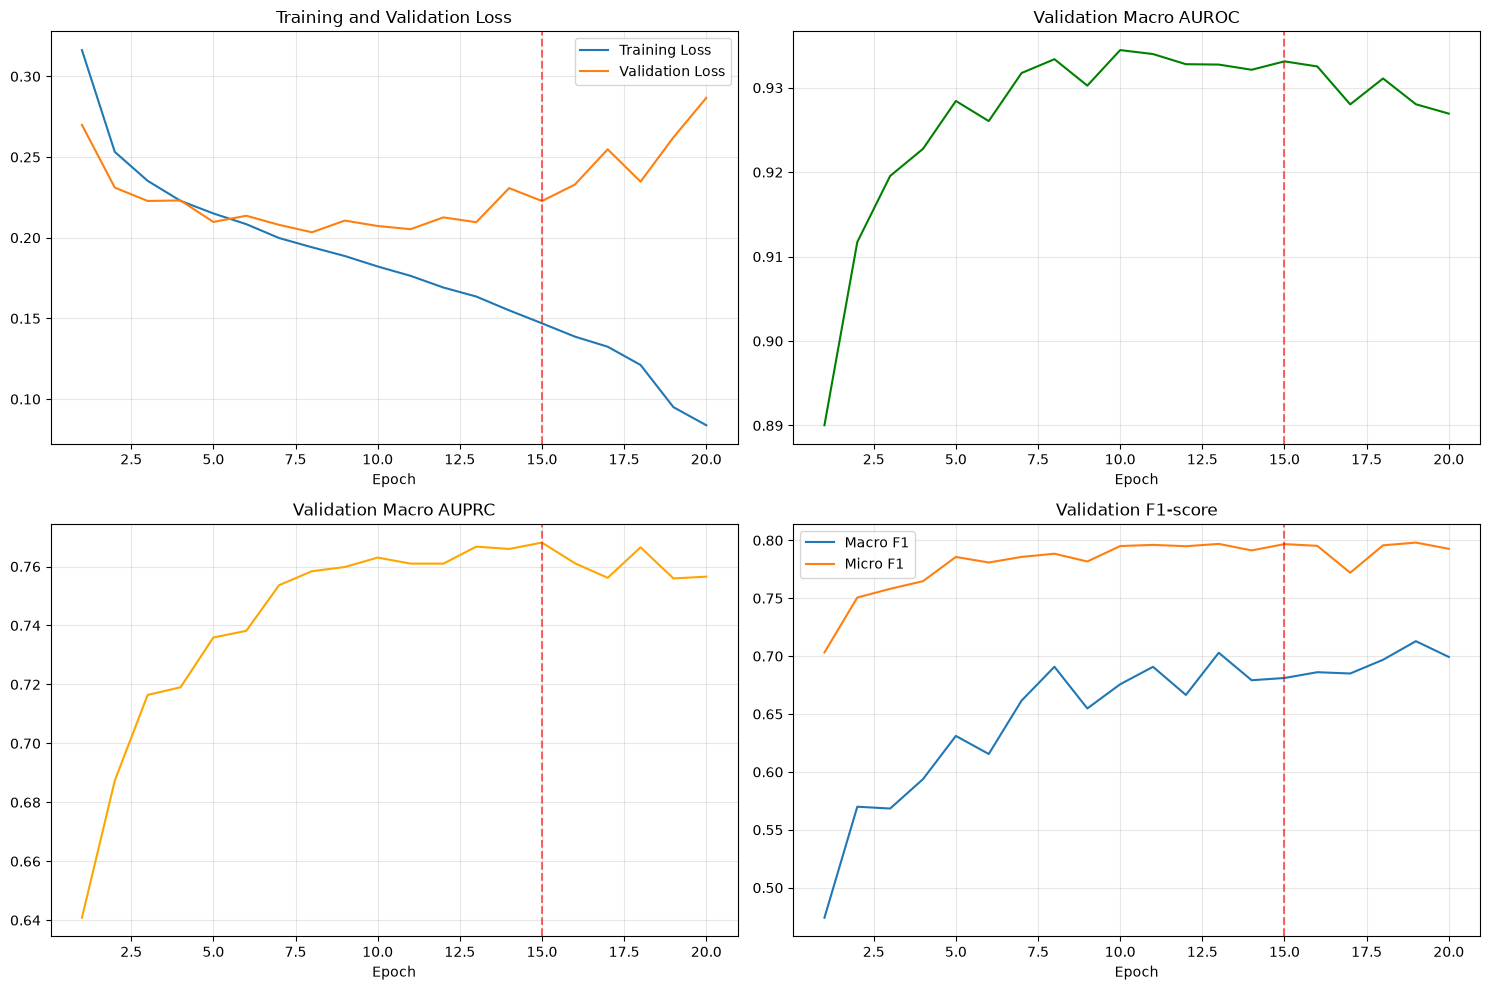

In [48]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Loss
axes[0, 0].plot(
    epochs, history["train_loss"], label="Training Loss"
)
axes[0, 0].plot(
    epochs, history["val_loss"], label="Validation Loss"
)
axes[0, 0].set_title("Training and Validation Loss")
axes[0, 0].legend()

# AUROC
axes[0, 1].plot(
    epochs, history["macro_auroc"], color="green"
)
axes[0, 1].set_title("Validation Macro AUROC")

# AUPRC
axes[1, 0].plot(
    epochs, history["macro_auprc"], color="orange"
)
axes[1, 0].set_title("Validation Macro AUPRC")

# F1
axes[1, 1].plot(
    epochs, history["macro_f1"], label="Macro F1"
)
axes[1, 1].plot(
    epochs, history["micro_f1"], label="Micro F1"
)
axes[1, 1].set_title("Validation F1-score")
axes[1, 1].legend()

for ax in axes.flat:

    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.axvline(
        best_epoch,
        color="red",
        linestyle="--",
        alpha=0.6
    )

plt.tight_layout()
plt.show()

In [49]:
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)

model.to(device)

cnn_metrics, cnn_val_targets, cnn_val_probs = evaluate_model(
    model,
    val_loader,
    criterion
)

cnn_val_preds = (cnn_val_probs >= 0.5).astype(int)

assert np.array_equal(cnn_val_targets, y_val)

print("Best CNN Validation Results")
print("-" * 40)

for metric, value in cnn_metrics.items():

    print(f"{metric}: {value:.4f}")

Best CNN Validation Results
----------------------------------------
loss: 0.2227
macro_auroc: 0.9331
macro_auprc: 0.7681
macro_f1: 0.6811
micro_f1: 0.7967


,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1
0,Logistic Regression,0.8718,0.6135,0.5167,0.6930
1,Random Forest,0.8720,0.6205,0.4467,0.6856
2,2D CNN,0.9331,0.7681,0.6811,0.7967


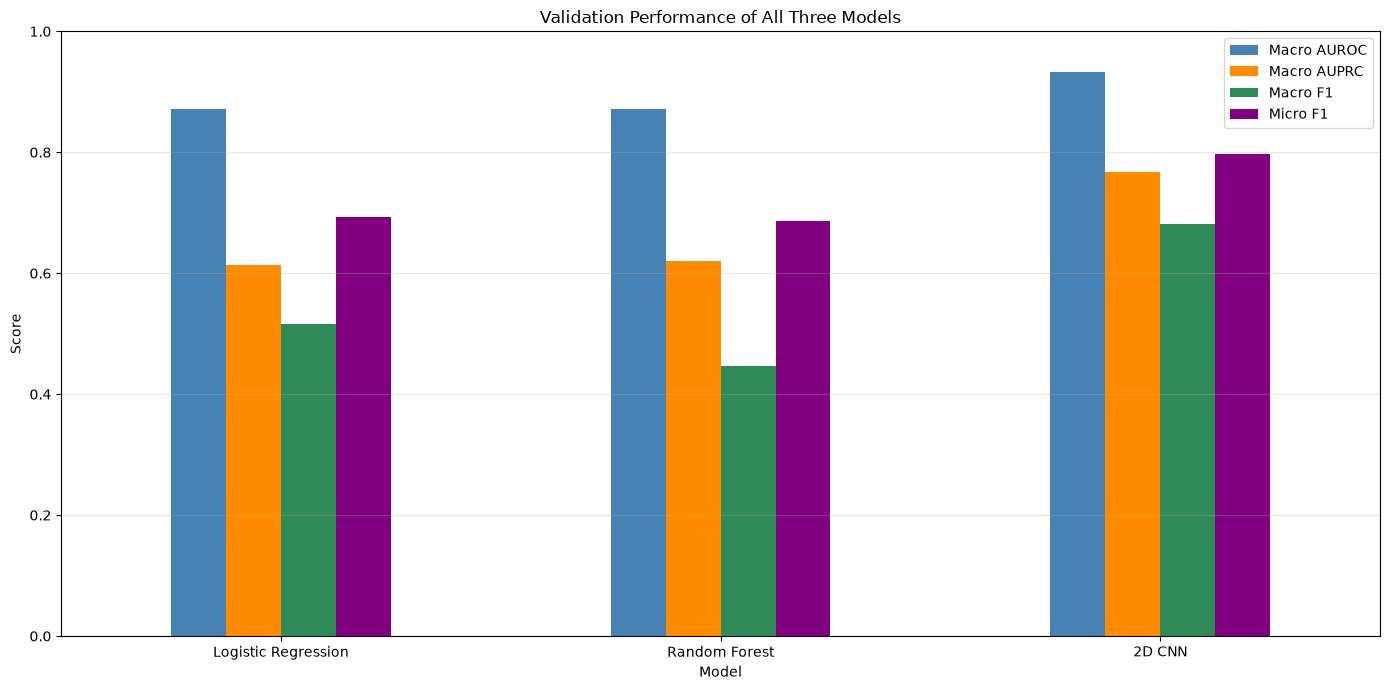

In [50]:
cnn_results = pd.DataFrame([{
    "Model": "2D CNN",
    "Macro AUROC": cnn_metrics["macro_auroc"],
    "Macro AUPRC": cnn_metrics["macro_auprc"],
    "Macro F1": cnn_metrics["macro_f1"],
    "Micro F1": cnn_metrics["micro_f1"]
}])

final_val_results = pd.concat(
    [results, cnn_results],
    ignore_index=True
)

display(final_val_results.round(4))

final_val_results.to_csv(
    DATA_DIR / "validation_model_comparison.csv",
    index=False
)

final_val_results.set_index("Model").plot(
    kind="bar",
    figsize=(14, 7),
    ylim=(0, 1),
    rot=0,
    color=["steelblue", "darkorange", "seagreen", "purple"]
)

plt.title("Validation Performance of All Three Models")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()